In [4]:
import os
# from google.colab import drive
# drive.mount("/content/drive")

from pathlib import Path
import sys
import torch
import numpy as np
import nibabel as nib

# ROOT = Path("/content/drive/MyDrive/ml360")
ROOT = Path("C:/Users/whate/Documents/Brain CT Hemorrage Detection")
DATA_ROOT = ROOT / "Dataset/labeled"
IMAGE_DIR = DATA_ROOT / "images"
MASK_DIR = DATA_ROOT / "ground_truths"
PREPROCESSING_FILE = ROOT / "week 2" / "preprocessing.py"

OUTPUT_DIR = ROOT / "week4_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert IMAGE_DIR.exists()
assert MASK_DIR.exists()
assert PREPROCESSING_FILE.exists()

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Preprocessing:", PREPROCESSING_FILE)
print("Output directory:", OUTPUT_DIR)

OSError: [WinError 4551] An Application Control policy has blocked this file. Error loading "c:\Users\whate\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\lib\c10.dll" or one of its dependencies.

In [50]:
import importlib.util

spec = importlib.util.spec_from_file_location(
    "week2_preprocessing",
    PREPROCESSING_FILE
)

preprocessing = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = preprocessing
spec.loader.exec_module(preprocessing)

print("Loaded:", preprocessing.__file__)
print("Window stack:", preprocessing.MultiHUWindowStack)
print("HU loader:", preprocessing.load_volume_as_hu)
print("Dataset:", preprocessing.BHSDSliceDataset)

Loaded: C:\Users\whate\Documents\Brain CT Hemorrage Detection\week 2\preprocessing.py
Window stack: <class 'week2_preprocessing.MultiHUWindowStack'>
HU loader: <function load_volume_as_hu at 0x0000017B00D766C0>
Dataset: <class 'week2_preprocessing.BHSDSliceDataset'>


In [51]:
image_files = sorted(IMAGE_DIR.glob("*.nii.gz"))
mask_files = sorted(MASK_DIR.glob("*.nii.gz"))

image_map = {p.name: p for p in image_files}
mask_map = {p.name: p for p in mask_files}
matched_names = sorted(set(image_map) & set(mask_map))

# assert len(matched_names) == 50, (
#     f"Expected 50 matched volumes; found {len(matched_names)}"
# )

name = matched_names[0]

volume = preprocessing.load_volume_as_hu(str(image_map[name]))
z = volume.shape[2] // 2
hu_slice = volume[:, :, z]

window_stack = preprocessing.MultiHUWindowStack()
image_3ch = window_stack(hu_slice)

print("Study:", name)
print("Volume shape:", volume.shape)
print("HU slice shape:", hu_slice.shape)
print("Windowed input shape:", image_3ch.shape)
print("Windowed value range:", image_3ch.min(), image_3ch.max())

assert image_3ch.shape == (3, volume.shape[0], volume.shape[1])
assert np.isfinite(image_3ch).all()
assert image_3ch.min() >= 0 and image_3ch.max() <= 1

Study: ID_0237f3c9_ID_40015688b9.nii.gz
Volume shape: (512, 512, 28)
HU slice shape: (512, 512)
Windowed input shape: (3, 512, 512)
Windowed value range: 0.0 1.0


In [52]:
import torch
import numpy as np
import nibabel as nib
from collections import Counter

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GiB"
    )

label_counts = Counter()
class_volumes = Counter()

for name in matched_names:
    mask = np.asanyarray(nib.load(str(mask_map[name])).dataobj)
    labels, counts = np.unique(mask, return_counts=True)

    for label, count in zip(labels, counts):
        label = int(label)
        label_counts[label] += int(count)

        if label != 0:
            class_volumes[label] += 1

print("\nMask values:", sorted(label_counts))
print("Volumes containing each foreground label:")
for label in sorted(class_volumes):
    print(f"Label {label}: {class_volumes[label]} volumes")

CUDA available: True
GPU: NVIDIA RTX PRO 5000 Blackwell
VRAM: 47.79 GiB

Mask values: [0, 1, 2, 3, 4, 5]
Volumes containing each foreground label:
Label 1: 23 volumes
Label 2: 127 volumes
Label 3: 104 volumes
Label 4: 109 volumes
Label 5: 70 volumes


In [53]:
from sklearn.model_selection import train_test_split
import json

SEED = 42
VAL_FRACTION = 0.20

all_studies = sorted(matched_names)

train_studies, val_studies = train_test_split(
    all_studies,
    test_size=VAL_FRACTION,
    random_state=SEED,
    shuffle=True
)

train_studies = sorted(train_studies)
val_studies = sorted(val_studies)

assert set(train_studies).isdisjoint(set(val_studies))
assert set(train_studies) | set(val_studies) == set(all_studies)

print("Training studies:", len(train_studies))
print("Validation studies:", len(val_studies))
print("Study overlap:", len(set(train_studies) & set(val_studies)))

split_info = {
    "seed": SEED,
    "validation_fraction": VAL_FRACTION,
    "purpose": "provisional Week 4 development smoke test",
    "training_studies": train_studies,
    "validation_studies": val_studies
}

split_path = OUTPUT_DIR / "development_split.json"
with open(split_path, "w") as f:
    json.dump(split_info, f, indent=2)

print("Saved split:", split_path)

Training studies: 153
Validation studies: 39
Study overlap: 0
Saved split: C:\Users\whate\Documents\Brain CT Hemorrage Detection\week4_outputs\development_split.json


In [54]:
def classes_in_studies(study_names):
    present = Counter()

    for name in study_names:
        mask = np.asanyarray(
            nib.load(str(mask_map[name])).dataobj
        )

        for label in np.unique(mask):
            label = int(label)
            if label != 0:
                present[label] += 1

    return dict(sorted(present.items()))

print("Training class coverage:", classes_in_studies(train_studies))
print("Validation class coverage:", classes_in_studies(val_studies))

Training class coverage: {1: 20, 2: 101, 3: 82, 4: 87, 5: 58}
Validation class coverage: {1: 3, 2: 26, 3: 22, 4: 22, 5: 12}


In [55]:
import numpy as np
import nibabel as nib
import torch
from torch.utils.data import Dataset, DataLoader

window_stack = preprocessing.MultiHUWindowStack()

def window_one_slice(hu_slice):
    """
    Input:  (H, W) HU slice
    Output: (3, H, W) windowed float32 array
    """
    result = window_stack(hu_slice)
    result = np.asarray(result, dtype=np.float32)

    assert result.ndim == 3, f"Expected 3D output, got {result.shape}"
    assert result.shape[0] == 3, f"Expected 3 channels, got {result.shape}"
    assert np.isfinite(result).all(), "Non-finite windowed values found"
    assert result.min() >= 0 and result.max() <= 1, (
        f"Unexpected range: {result.min()} to {result.max()}"
    )

    return result

In [56]:
from collections import OrderedDict

class BHSD25DDataset(Dataset):
    """2.5D dataset with optional per-volume caching and negative-slice sampling."""

    def __init__(
        self,
        study_names,
        image_map,
        mask_map,
        cache_size=2,
        negative_ratio=None,
        seed=42,
    ):
        self.study_names = list(study_names)
        self.image_map = image_map
        self.mask_map = mask_map
        self.cache_size = cache_size
        self.cache = OrderedDict()
        self.samples = []

        rng = np.random.default_rng(seed)
        for name in self.study_names:
            image_nii = nib.load(str(self.image_map[name]))
            mask_nii = nib.load(str(self.mask_map[name]))

            if image_nii.shape != mask_nii.shape:
                raise ValueError(f"Shape mismatch: {name}")
            if len(image_nii.shape) != 3:
                raise ValueError(f"Expected 3D volume: {name}")

            if negative_ratio is None:
                selected_slices = np.arange(image_nii.shape[2])
            else:
                mask_volume = np.asanyarray(mask_nii.dataobj)
                positive = np.flatnonzero(
                    np.any(mask_volume != 0, axis=(0, 1))
                )
                negative = np.flatnonzero(
                    ~np.any(mask_volume != 0, axis=(0, 1))
                )
                max_negative = int(len(positive) * negative_ratio)
                if max_negative and len(negative) > max_negative:
                    negative = rng.choice(
                        negative, size=max_negative, replace=False
                    )
                selected_slices = np.sort(np.concatenate((positive, negative)))

            self.samples.extend((name, int(z)) for z in selected_slices)

        print(
            f"Created dataset with {len(self.study_names)} studies "
            f"and {len(self.samples)} slices."
        )

    def __len__(self):
        return len(self.samples)

    def _load_study(self, name):
        if name in self.cache:
            self.cache.move_to_end(name)
            return self.cache[name]

        volume_hu = preprocessing.load_volume_as_hu(
            str(self.image_map[name])
        )
        mask = np.asanyarray(
            nib.load(str(self.mask_map[name])).dataobj
        )

        if volume_hu.shape != mask.shape:
            raise ValueError(
                f"HU volume/mask mismatch for {name}: "
                f"{volume_hu.shape} vs {mask.shape}"
            )

        unique_labels = np.unique(mask)
        if not np.isin(unique_labels, np.arange(6)).all():
            raise ValueError(
                f"Unexpected mask labels in {name}: {unique_labels}"
            )

        item = (
            np.asarray(volume_hu, dtype=np.float32),
            np.asarray(mask, dtype=np.int64)
        )
        self.cache[name] = item

        if self.cache_size is not None:
            while len(self.cache) > self.cache_size:
                self.cache.popitem(last=False)

        return item

    def __getitem__(self, index):
        name, z = self.samples[index]
        volume_hu, mask_volume = self._load_study(name)
        depth = volume_hu.shape[2]
        neighbor_indices = [max(0, z - 1), z, min(depth - 1, z + 1)]

        image = np.concatenate(
            [window_one_slice(volume_hu[:, :, slice_idx])
             for slice_idx in neighbor_indices],
            axis=0
        )
        target = mask_volume[:, :, z]

        return (
            torch.from_numpy(np.ascontiguousarray(image)).float(),
            torch.from_numpy(np.ascontiguousarray(target)).long()
        )

In [57]:
from torch.utils.data import DataLoader

# Empty slices are useful for calibration, but training on every one wastes
# most steps. Keep all positive slices and at most two negatives per positive.
TRAIN_NEGATIVE_RATIO = 2
# Set BHSD_CACHE_ALL=1 only when RAM is sufficient; this disables workers to
# avoid duplicating the full cache in Windows worker processes.
CACHE_ALL_VOLUMES = os.environ.get("BHSD_CACHE_ALL", "0") == "1"
CACHE_SIZE = None if CACHE_ALL_VOLUMES else 8

train_ds = BHSD25DDataset(
    train_studies,
    image_map,
    mask_map,
    cache_size=CACHE_SIZE,
    negative_ratio=TRAIN_NEGATIVE_RATIO,
    seed=SEED,
)

val_ds = BHSD25DDataset(
    val_studies,
    image_map,
    mask_map,
    cache_size=CACHE_SIZE,
    negative_ratio=None,
)

if torch.cuda.is_available():
    total_vram_gib = (
        torch.cuda.get_device_properties(0).total_memory / 1024**3
    )
    BATCH_SIZE = 64 if total_vram_gib >= 40 else 16
else:
    BATCH_SIZE = 4

available_workers = os.cpu_count() or 1
NUM_WORKERS = 0 if CACHE_ALL_VOLUMES else min(8, available_workers)

loader_kwargs = {
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
    "persistent_workers": NUM_WORKERS > 0,
}
if NUM_WORKERS > 0:
    loader_kwargs["prefetch_factor"] = 2

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **loader_kwargs,
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    **loader_kwargs,
)

print("Training slices:", len(train_ds))
print("Validation slices:", len(val_ds))
print("Batch size:", BATCH_SIZE)
print("DataLoader workers:", NUM_WORKERS)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Created dataset with 153 studies and 4088 slices.
Created dataset with 39 studies and 1376 slices.
Training slices: 4088
Validation slices: 1376
Batch size: 64
DataLoader workers: 8
Training batches: 64
Validation batches: 22


In [58]:
name = "ID_089596a9_ID_ea71b57820.nii.gz"

image_nii = nib.load(image_map[name])
mask_nii = nib.load(mask_map[name])

print("Image path:", image_map[name])
print("Mask path:", mask_map[name])
print("Image shape:", image_nii.shape)
print("Mask shape:", mask_nii.shape)
print("Image affine:\n", image_nii.affine)
print("Mask affine:\n", mask_nii.affine)
print("Max affine difference:",
      np.max(np.abs(image_nii.affine - mask_nii.affine)))

Image path: C:\Users\whate\Documents\Brain CT Hemorrage Detection\Dataset\labeled\images\ID_089596a9_ID_ea71b57820.nii.gz
Mask path: C:\Users\whate\Documents\Brain CT Hemorrage Detection\Dataset\labeled\ground_truths\ID_089596a9_ID_ea71b57820.nii.gz
Image shape: (512, 512, 40)
Mask shape: (512, 512, 40)
Image affine:
 [[-4.88281012e-01  0.00000000e+00  0.00000000e+00  1.53500000e+02]
 [ 0.00000000e+00  5.19617736e-01 -2.98023224e-07 -1.00402634e+02]
 [ 0.00000000e+00  1.67001829e-01  2.34923339e+00 -3.80435143e+01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]
Mask affine:
 [[-4.88281012e-01  0.00000000e+00  0.00000000e+00  1.53500000e+02]
 [ 0.00000000e+00  4.82390778e-01 -3.87144390e-01 -1.00402634e+02]
 [ 0.00000000e+00  7.56140441e-02  2.46984387e+00 -3.80435143e+01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]
Max affine difference: 0.3871440922309828


In [59]:
# Shut down workers from the previous loaders, if any.
for loader in (train_loader, val_loader):
    iterator = getattr(loader, "_iterator", None)
    if iterator is not None:
        iterator._shutdown_workers()

# Avoid duplicated NIfTI caches and multiprocessing failures on Windows.
train_ds.cache.clear()
val_ds.cache.clear()
train_ds.cache_size = 2
val_ds.cache_size = 2

safe_loader_kwargs = {
    "num_workers": 0,
    "pin_memory": torch.cuda.is_available(),
}

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **safe_loader_kwargs,
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    **safe_loader_kwargs,
)

images, masks = next(iter(train_loader))

print("Input shape:", tuple(images.shape))
print("Target shape:", tuple(masks.shape))
print("Input dtype:", images.dtype)
print("Target dtype:", masks.dtype)
print("Input min/max:", images.min().item(), images.max().item())
print("Mask labels:", torch.unique(masks).tolist())

assert images.ndim == 4
assert images.shape[1] == 9
assert masks.ndim == 3
assert images.shape[0] == masks.shape[0]
assert images.shape[-2:] == masks.shape[-2:]
assert torch.isfinite(images).all()
assert set(torch.unique(masks).tolist()).issubset(set(range(6)))

print("\nPASS: 2.5D batch validation.")

Input shape: (64, 9, 512, 512)
Target shape: (64, 512, 512)
Input dtype: torch.float32
Target dtype: torch.int64
Input min/max: 0.0 1.0
Mask labels: [0, 2, 3, 4, 5]

PASS: 2.5D batch validation.


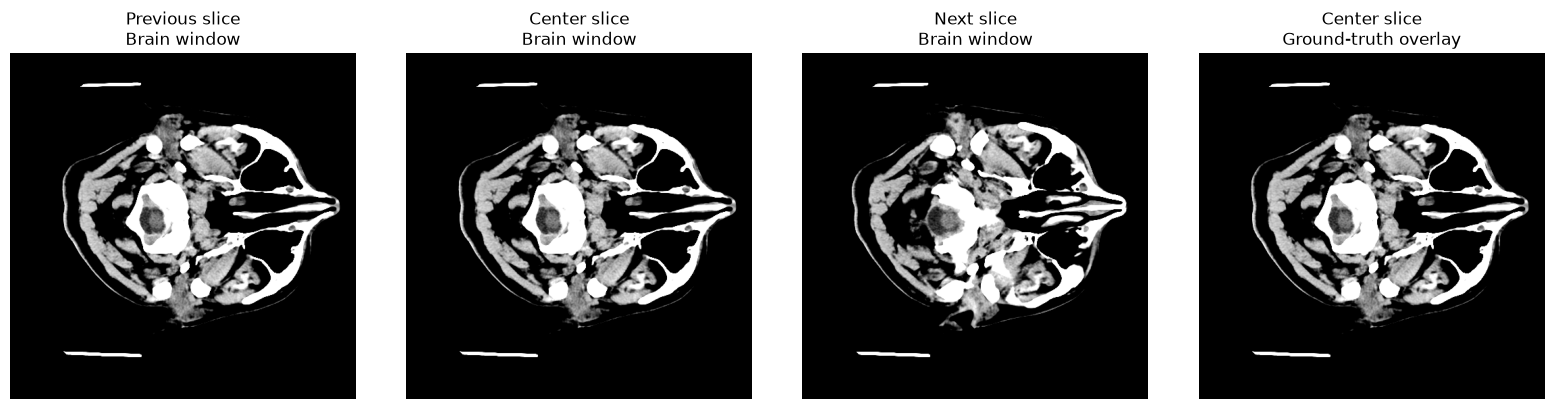

In [60]:
import matplotlib.pyplot as plt

image, target = train_ds[0]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(image[0].numpy(), cmap="gray")
axes[0].set_title("Previous slice\nBrain window")

axes[1].imshow(image[3].numpy(), cmap="gray")
axes[1].set_title("Center slice\nBrain window")

axes[2].imshow(image[6].numpy(), cmap="gray")
axes[2].set_title("Next slice\nBrain window")

axes[3].imshow(image[3].numpy(), cmap="gray")
axes[3].imshow(
    np.ma.masked_where(target.numpy() == 0, target.numpy()),
    cmap="tab10", vmin=0, vmax=5, alpha=0.6,
    interpolation="nearest"
)
axes[3].set_title("Center slice\nGround-truth overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [61]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dropout_p=0.0):
        super().__init__()

        layers = [
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        ]

        if dropout_p > 0:
            layers.append(nn.Dropout2d(p=dropout_p))

        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)

In [62]:
class UNet25D(nn.Module):
    def __init__(
        self,
        in_channels=9,
        num_classes=6,
        base_channels=16,
        dropout_p=0.2
    ):
        super().__init__()

        c1 = base_channels
        c2 = base_channels * 2
        c3 = base_channels * 4
        c4 = base_channels * 8

        self.pool = nn.MaxPool2d(2)

        # Encoder
        self.enc1 = ConvBlock(in_channels, c1)
        self.enc2 = ConvBlock(c1, c2)
        self.enc3 = ConvBlock(c2, c3, dropout_p)

        # Bottleneck
        self.bottleneck = ConvBlock(c3, c4, dropout_p)

        # Decoder
        self.up3 = nn.ConvTranspose2d(c4, c3, 2, stride=2)
        self.dec3 = ConvBlock(c3 * 2, c3, dropout_p)

        self.up2 = nn.ConvTranspose2d(c3, c2, 2, stride=2)
        self.dec2 = ConvBlock(c2 * 2, c2, dropout_p)

        self.up1 = nn.ConvTranspose2d(c2, c1, 2, stride=2)
        self.dec1 = ConvBlock(c1 * 2, c1)

        # Six output logits: background + five foreground classes
        self.segmentation_head = nn.Conv2d(c1, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        # Return raw logits; do not apply softmax here.
        return self.segmentation_head(d1)

In [63]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = UNet25D(
    in_channels=9,
    num_classes=6,
    base_channels=16,
    dropout_p=0.2
).to(DEVICE)

COMPILE_MODEL = DEVICE.type == "cuda" and hasattr(torch, "compile")
if COMPILE_MODEL:
    model = torch.compile(model, mode="max-autotune")

num_parameters = sum(
    parameter.numel() for parameter in model.parameters()
)

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
print(f"Total parameters: {num_parameters:,}")
print("Architecture: 2.5D U-Net")
print("Input channels: 9")
print("Output classes: 6")
print("torch.compile:", COMPILE_MODEL)

W1019 19:09:38.399000 46888 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Device: cuda
GPU: NVIDIA RTX PRO 5000 Blackwell
Trainable parameters: 483,686
Total parameters: 483,686
Architecture: 2.5D U-Net
Input channels: 9
Output classes: 6
torch.compile: True


In [65]:
from collections import Counter

images, masks = next(iter(train_loader))

images = images.to(DEVICE)
masks = masks.to(DEVICE)

# Check output shape.
model.eval()

with torch.no_grad():
    # PyTorch Inductor is failing on this convolution.
    # Use the original eager model for compatibility.
    model = getattr(model, "_orig_mod", model)
    logits = model(images)

print("Input:", tuple(images.shape))
print("Target:", tuple(masks.shape))
print("Logits:", tuple(logits.shape))

assert logits.shape == (
    images.shape[0], 6, images.shape[2], images.shape[3]
)

# Check dropout configuration.
dropout_layers = [
    layer for layer in model.modules()
    if isinstance(layer, nn.Dropout2d)
]

print("Dropout2d layers:", len(dropout_layers))
print("Dropout probabilities:", [layer.p for layer in dropout_layers])

assert len(dropout_layers) > 0
assert all(layer.p >= 0.2 for layer in dropout_layers)

print("\nPASS: output shape and dropout configuration.")

Input: (64, 9, 512, 512)
Target: (64, 512, 512)
Logits: (64, 6, 512, 512)
Dropout2d layers: 4
Dropout probabilities: [0.2, 0.2, 0.2, 0.2]

PASS: output shape and dropout configuration.


In [66]:
def enable_dropout_only(model):
    model.eval()

    for module in model.modules():
        if isinstance(module, nn.Dropout2d):
            module.train()


enable_dropout_only(model)

with torch.no_grad():
    prediction_1 = model(images)
    prediction_2 = model(images)

difference = (prediction_1 - prediction_2).abs().mean().item()

print("Mean absolute difference between predictions:", difference)

assert difference > 0, (
    "Predictions are identical. Check that dropout is present and active."
)

print("PASS: dropout produces stochastic predictions.")

Mean absolute difference between predictions: 7.90946141933091e-05
PASS: dropout produces stochastic predictions.


# CE + Dice Loss


In [67]:
import torch
import torch.nn as nn
import torch.nn.functional as F

NUM_CLASSES = 6
DICE_WEIGHT = 1.0

def multiclass_dice_loss(logits, targets, eps=1e-6):
    """
    logits:  (B, 6, H, W), raw model outputs
    targets: (B, H, W), integer IDs 0–5

    Computes soft Dice loss over foreground classes 1–5.
    """
    probs = torch.softmax(logits, dim=1)

    one_hot = F.one_hot(
        targets, num_classes=NUM_CLASSES
    ).permute(0, 3, 1, 2).float()

    # Aggregate across batch and spatial dimensions.
    dims = (0, 2, 3)

    intersection = (probs * one_hot).sum(dim=dims)
    denominator = probs.sum(dim=dims) + one_hot.sum(dim=dims)

    dice_per_class = (
        2.0 * intersection + eps
    ) / (
        denominator + eps
    )

    # Exclude background from the Dice component.
    foreground_dice = dice_per_class[1:]

    return 1.0 - foreground_dice.mean()


def combined_loss(logits, targets, dice_weight=DICE_WEIGHT):
    ce = F.cross_entropy(logits, targets)
    dice = multiclass_dice_loss(logits, targets)

    total = ce + dice_weight * dice

    return total, {
        "cross_entropy": ce.detach().item(),
        "dice_loss": dice.detach().item(),
        "total_loss": total.detach().item()
    }

In [68]:
import copy

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

# Keep a copy of one parameter to verify that it changes.
parameter_before = (
    next(model.parameters()).detach().clone()
)

model.train()
optimizer.zero_grad(set_to_none=True)

images, masks = next(iter(train_loader))
images = images.to(DEVICE)
masks = masks.to(DEVICE)

logits = model(images)
loss, loss_parts = combined_loss(logits, masks)

print("Loss components:")
for name, value in loss_parts.items():
    print(f"{name}: {value:.6f}")

assert torch.isfinite(loss), "Loss is NaN or Inf."

loss.backward()

# Verify gradients exist and are finite.
gradients = [
    p.grad for p in model.parameters()
    if p.grad is not None
]

assert gradients, "No gradients were produced."
assert all(torch.isfinite(g).all() for g in gradients), (
    "Non-finite gradients detected."
)


gradient_norm = torch.sqrt(sum(
    torch.sum(g.detach() ** 2) for g in gradients
)).item()

print("Gradient norm:", gradient_norm)

optimizer.step()

parameter_after = next(model.parameters()).detach()
parameter_change = (
    parameter_after - parameter_before
).abs().max().item()

print("Maximum parameter change:", parameter_change)

assert parameter_change > 0, "Parameters did not update."

print("\nPASS: forward pass, loss, gradients and optimizer update.")

Loss components:
cross_entropy: 1.673910
dice_loss: 0.998900
total_loss: 2.672811
Gradient norm: 1.7343791723251343
Maximum parameter change: 0.0010000169277191162

PASS: forward pass, loss, gradients and optimizer update.


In [69]:
%pip install tensorboard

Note: you may need to restart the kernel to use updated packages.


In [70]:
import json
import time
from torch.utils.tensorboard import SummaryWriter

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
LOG_DIR = OUTPUT_DIR / "tensorboard"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

writer = SummaryWriter(str(LOG_DIR))

EPOCHS = 35

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

CLASS_NAMES = ["Background", "Label_1", "Label_2",
               "Label_3", "Label_4", "Label_5"]

print("Checkpoints:", CHECKPOINT_DIR)
print("TensorBoard:", LOG_DIR)

Checkpoints: C:\Users\whate\Documents\Brain CT Hemorrage Detection\week4_outputs\checkpoints
TensorBoard: C:\Users\whate\Documents\Brain CT Hemorrage Detection\week4_outputs\tensorboard


In [71]:
import numpy as np

@torch.no_grad()
def validate(model, loader):
    model.eval()

    total_loss = 0.0
    batches = 0

    # Accumulate hard-prediction Dice across the full validation set.
    intersections = torch.zeros(NUM_CLASSES, dtype=torch.float64)
    denominators = torch.zeros(NUM_CLASSES, dtype=torch.float64)

    for images, masks in loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=AMP_DTYPE,
            enabled=AMP_ENABLED,
        ):
            logits = model(images)
            loss, _ = combined_loss(logits, masks)

        total_loss += loss.item()
        batches += 1

        predictions = logits.argmax(dim=1)

        for cls in range(NUM_CLASSES):
            p = predictions == cls
            t = masks == cls

            intersections[cls] += (p & t).sum().item()
            denominators[cls] += p.sum().item() + t.sum().item()

    if batches == 0:
        raise RuntimeError("Validation loader is empty.")

    per_class_dice = {}

    for cls, name in enumerate(CLASS_NAMES):
        denominator = denominators[cls].item()

        # NaN means absent from both prediction and target.
        per_class_dice[name] = (
            2 * intersections[cls].item() / denominator
            if denominator > 0 else float("nan")
        )

    foreground_scores = [
        per_class_dice[CLASS_NAMES[i]]
        for i in range(1, NUM_CLASSES)
        if np.isfinite(per_class_dice[CLASS_NAMES[i]])
    ]

    macro_dice = (
        float(np.mean(foreground_scores))
        if foreground_scores else float("nan")
    )

    return {
        "loss": total_loss / batches,
        "per_class_dice": per_class_dice,
        "macro_dice": macro_dice
    }

In [72]:
AMP_ENABLED = DEVICE.type == "cuda"
AMP_DTYPE = (
    torch.bfloat16
    if AMP_ENABLED and torch.cuda.is_bf16_supported()
    else torch.float16
)
scaler = torch.amp.GradScaler(
    "cuda", enabled=AMP_ENABLED and AMP_DTYPE == torch.float16
)

history = []
best_macro_dice = -float("inf")
best_path = CHECKPOINT_DIR / "best_model.pt"
last_path = CHECKPOINT_DIR / "last_model.pt"

for epoch in range(1, EPOCHS + 1):
    start = time.time()

    model.train()
    train_loss_sum = 0.0
    train_batches = 0

    for images, masks in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=AMP_DTYPE,
            enabled=AMP_ENABLED,
        ):
            logits = model(images)
            loss, _ = combined_loss(logits, masks)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite training loss at epoch {epoch}.")

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_sum += loss.detach().item()
        train_batches += 1

    if train_batches == 0:
        raise RuntimeError("Training loader is empty.")

    scheduler.step()
    train_loss = train_loss_sum / train_batches
    val_metrics = validate(model, val_loader)
    current_lr = optimizer.param_groups[0]["lr"]

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_macro_dice": val_metrics["macro_dice"],
        "learning_rate": current_lr,
        "seconds": time.time() - start,
        "amp_dtype": str(AMP_DTYPE) if AMP_ENABLED else "disabled",
    }
    history.append(record)

    writer.add_scalar("Loss/train", train_loss, epoch)
    writer.add_scalar("Loss/validation", val_metrics["loss"], epoch)
    writer.add_scalar("Dice/foreground_macro", val_metrics["macro_dice"], epoch)
    writer.add_scalar("LearningRate", current_lr, epoch)

    for name, score in val_metrics["per_class_dice"].items():
        writer.add_scalar(f"Dice/{name}", score, epoch)

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_macro_dice": best_macro_dice,
        "training_config": {
            "amp_enabled": AMP_ENABLED,
            "amp_dtype": str(AMP_DTYPE) if AMP_ENABLED else "disabled",
            "compiled": COMPILE_MODEL,
            "batch_size": BATCH_SIZE,
            "train_negative_ratio": TRAIN_NEGATIVE_RATIO,
        },
        "metrics": record,
    }
    torch.save(checkpoint, last_path)

    if val_metrics["macro_dice"] > best_macro_dice:
        best_macro_dice = val_metrics["macro_dice"]
        checkpoint["best_macro_dice"] = best_macro_dice
        torch.save(checkpoint, best_path)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train={train_loss:.4f} | "
        f"val={val_metrics['loss']:.4f} | "
        f"macro_dice={val_metrics['macro_dice']:.4f} | "
        f"lr={current_lr:.2e} | "
        f"time={record['seconds']:.1f}s"
    )

writer.close()
print("Best checkpoint:", best_path)
print("Latest checkpoint:", last_path)

Epoch 01/35 | train=2.0219 | val=1.7126 | macro_dice=0.0000 | lr=9.98e-04 | time=852.8s
Epoch 02/35 | train=1.4123 | val=1.2881 | macro_dice=0.0000 | lr=9.92e-04 | time=853.5s
Epoch 03/35 | train=1.1779 | val=1.1262 | macro_dice=0.0000 | lr=9.82e-04 | time=845.4s
Epoch 04/35 | train=1.0891 | val=1.0650 | macro_dice=0.0000 | lr=9.68e-04 | time=857.1s
Epoch 05/35 | train=1.0483 | val=1.0335 | macro_dice=0.0000 | lr=9.50e-04 | time=864.9s
Epoch 06/35 | train=1.0225 | val=1.0154 | macro_dice=0.0000 | lr=9.29e-04 | time=850.3s
Epoch 07/35 | train=1.0028 | val=1.0014 | macro_dice=0.0000 | lr=9.05e-04 | time=842.4s
Epoch 08/35 | train=0.9869 | val=0.9937 | macro_dice=0.0000 | lr=8.77e-04 | time=848.2s
Epoch 09/35 | train=0.9733 | val=0.9798 | macro_dice=0.0000 | lr=8.46e-04 | time=850.9s
Epoch 10/35 | train=0.9604 | val=0.9782 | macro_dice=0.0519 | lr=8.12e-04 | time=847.6s
Epoch 11/35 | train=0.9372 | val=0.9307 | macro_dice=0.1362 | lr=7.75e-04 | time=849.6s
Epoch 12/35 | train=0.8894 | val

,epoch,train_loss,val_loss,val_macro_dice
0,1,2.021921,1.712596,0.000000
1,2,1.412330,1.288085,0.000000
2,3,1.177897,1.126158,0.000000
3,4,1.089096,1.065009,0.000000
4,5,1.048318,1.033503,0.000000
5,6,1.022517,1.015358,0.000000
6,7,1.002808,1.001369,0.000000
7,8,0.986875,0.993718,0.000000
8,9,0.973322,0.979845,0.000000
9,10,0.960380,0.978174,0.051947


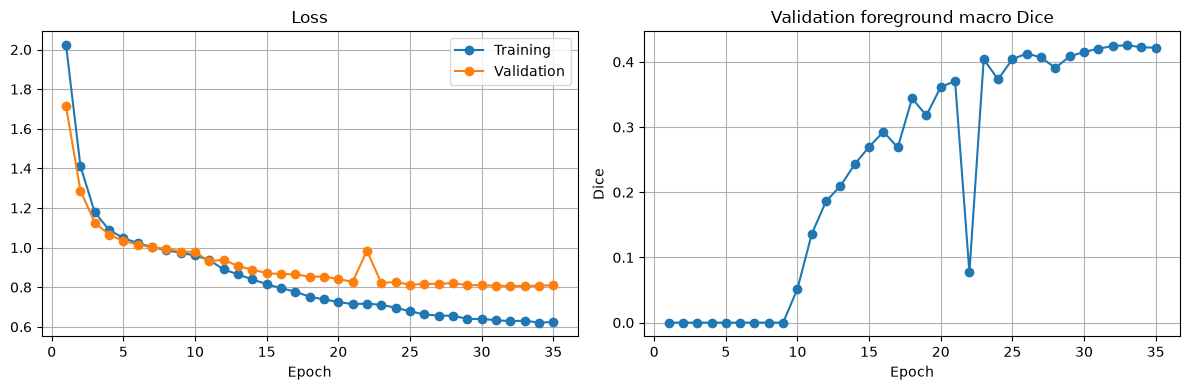

In [74]:
import matplotlib.pyplot as plt
import pandas as pd

history_df = pd.DataFrame([
    {
        "epoch": item["epoch"],
        "train_loss": item["train_loss"],
        "val_loss": item["val_loss"],
        "val_macro_dice": item["val_macro_dice"]
    }
    for item in history
])

display(history_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"],
             marker="o", label="Training")
axes[0].plot(history_df["epoch"], history_df["val_loss"],
             marker="o", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_df["epoch"], history_df["val_macro_dice"],
             marker="o")
axes[1].set_title("Validation foreground macro Dice")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice")
axes[1].grid(True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "smoke_test_curves.png", dpi=150)
plt.show()

Ground-truth pixel counts:
Class 0: 16,743,150
Class 1: 0
Class 2: 6,683
Class 3: 6,048
Class 4: 5,469
Class 5: 15,866

Predicted pixel counts:
Class 0: 16,746,729
Class 1: 3,182
Class 2: 2,844
Class 3: 9,585
Class 4: 4,684
Class 5: 10,192

Confusion matrix (rows=true, columns=predicted):
[[16735903      919      268     1527     2164     2369]
 [       0        0        0        0        0        0]
 [     447        0     2218     3842      176        0]
 [    1473        0      358     4216        0        1]
 [    3868       43        0        0     1518       40]
 [    5038     2220        0        0      826     7782]]


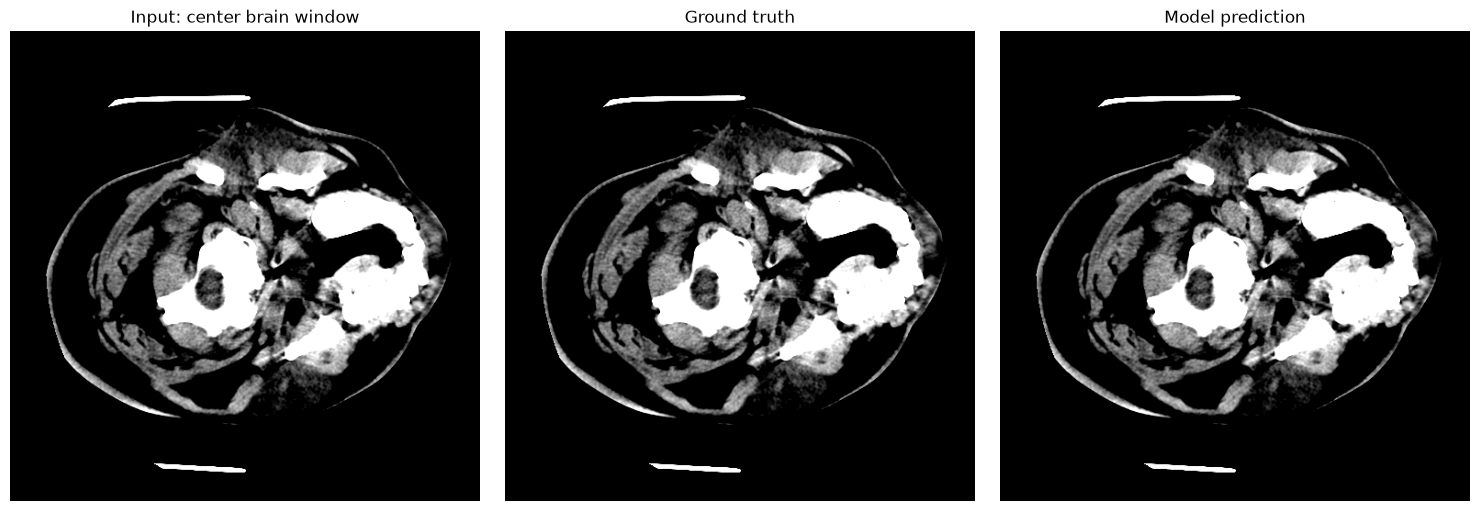

In [75]:
import torch
import numpy as np
import matplotlib.pyplot as plt

checkpoint = torch.load(
    best_path,
    map_location=DEVICE,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

images, masks = next(iter(val_loader))
images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    logits = model(images)
    predictions = logits.argmax(dim=1)

print("Ground-truth pixel counts:")
for cls in range(6):
    print(f"Class {cls}: {(masks == cls).sum().item():,}")

print("\nPredicted pixel counts:")
for cls in range(6):
    print(f"Class {cls}: {(predictions == cls).sum().item():,}")

# Confusion matrix: rows = ground truth, columns = prediction.
confusion = torch.zeros((6, 6), dtype=torch.int64)

for true_cls in range(6):
    for pred_cls in range(6):
        confusion[true_cls, pred_cls] = (
            ((masks == true_cls) & (predictions == pred_cls))
            .sum().cpu()
        )

print("\nConfusion matrix (rows=true, columns=predicted):")
print(confusion.numpy())

# Visualize the first sample in the validation batch.
img = images[0, 3].cpu().numpy()  # Center slice, brain window
gt = masks[0].cpu().numpy()
pred = predictions[0].cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Input: center brain window")

axes[1].imshow(img, cmap="gray")
axes[1].imshow(
    np.ma.masked_where(gt == 0, gt),
    cmap="tab10", vmin=0, vmax=5, alpha=0.65,
    interpolation="nearest"
)
axes[1].set_title("Ground truth")

axes[2].imshow(img, cmap="gray")
axes[2].imshow(
    np.ma.masked_where(pred == 0, pred),
    cmap="tab10", vmin=0, vmax=5, alpha=0.65,
    interpolation="nearest"
)
axes[2].set_title("Model prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [76]:
import numpy as np
import nibabel as nib

positive_slices = []
negative_slices = []

for name in val_studies:
    mask_vol = np.asanyarray(
        nib.load(str(mask_map[name])).dataobj
    )

    for z in range(mask_vol.shape[2]):
        labels, counts = np.unique(
            mask_vol[:, :, z], return_counts=True
        )

        foreground_pixels = int(
            counts[labels != 0].sum()
        )

        record = {
            "study": name,
            "slice": z,
            "foreground_pixels": foreground_pixels,
            "labels": np.unique(mask_vol[:, :, z]).astype(int).tolist()
        }

        if foreground_pixels > 0:
            positive_slices.append(record)
        else:
            negative_slices.append(record)

print("Validation slices with foreground:", len(positive_slices))
print("Background-only validation slices:", len(negative_slices))

print("\nFirst 10 positive slices:")
for item in positive_slices[:10]:
    print(item)

Validation slices with foreground: 486
Background-only validation slices: 890

First 10 positive slices:
{'study': 'ID_0492041f_ID_b4fcf2f799.nii.gz', 'slice': 8, 'foreground_pixels': 434, 'labels': [0, 3]}
{'study': 'ID_0492041f_ID_b4fcf2f799.nii.gz', 'slice': 9, 'foreground_pixels': 225, 'labels': [0, 3]}
{'study': 'ID_0492041f_ID_b4fcf2f799.nii.gz', 'slice': 10, 'foreground_pixels': 176, 'labels': [0, 3]}
{'study': 'ID_0492041f_ID_b4fcf2f799.nii.gz', 'slice': 11, 'foreground_pixels': 142, 'labels': [0, 3]}
{'study': 'ID_0492041f_ID_b4fcf2f799.nii.gz', 'slice': 12, 'foreground_pixels': 730, 'labels': [0, 3]}
{'study': 'ID_0492041f_ID_b4fcf2f799.nii.gz', 'slice': 13, 'foreground_pixels': 626, 'labels': [0, 3]}
{'study': 'ID_0492041f_ID_b4fcf2f799.nii.gz', 'slice': 14, 'foreground_pixels': 501, 'labels': [0, 3]}
{'study': 'ID_0492041f_ID_b4fcf2f799.nii.gz', 'slice': 15, 'foreground_pixels': 1207, 'labels': [0, 3]}
{'study': 'ID_0492041f_ID_b4fcf2f799.nii.gz', 'slice': 16, 'foreground_p

Study: ID_0492041f_ID_b4fcf2f799.nii.gz
Slice: 8
Ground-truth labels: [0 3]
Predicted labels: [0 3]


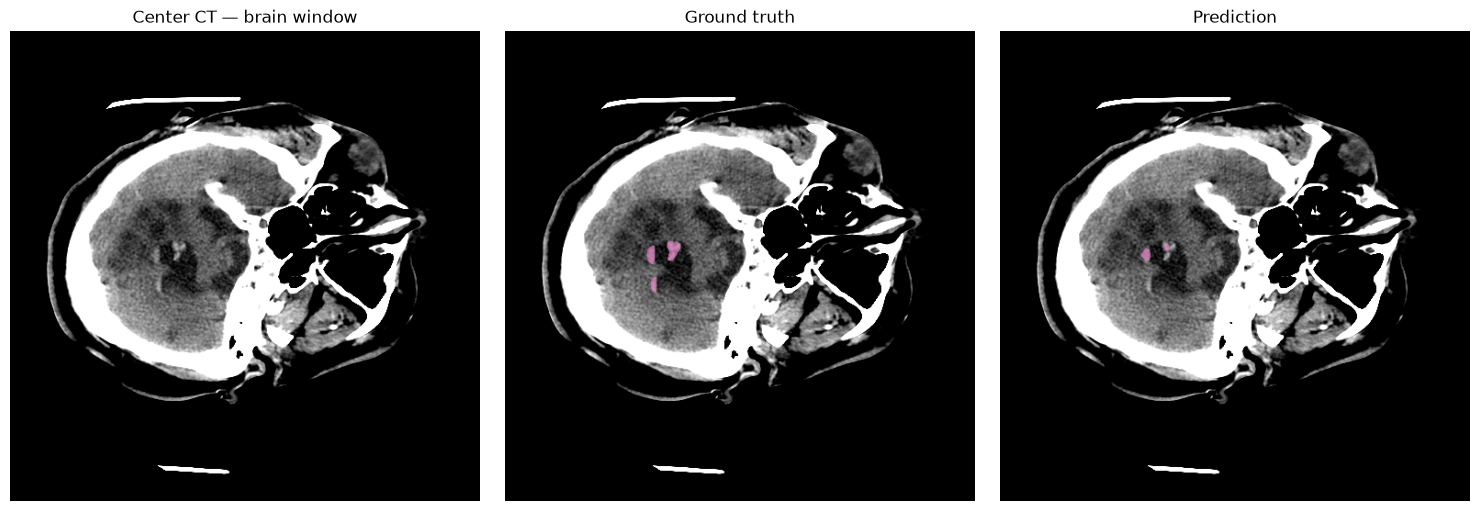

In [77]:
assert positive_slices, (
    "No positive validation slices found. Check masks and split."
)

item = positive_slices[0]
name = item["study"]
z = item["slice"]

hu_volume = preprocessing.load_volume_as_hu(
    str(image_map[name])
)
mask_volume = np.asanyarray(
    nib.load(str(mask_map[name])).dataobj
)

windowed = window_one_slice(hu_volume[:, :, z])

# Build the same 2.5D input used during training.
depth = hu_volume.shape[2]
indices = [max(0, z - 1), z, min(depth - 1, z + 1)]

channels = [
    window_one_slice(hu_volume[:, :, idx])
    for idx in indices
]

x = torch.from_numpy(
    np.concatenate(channels, axis=0)
).float().unsqueeze(0).to(DEVICE)

model.eval()
with torch.no_grad():
    pred = model(x).argmax(dim=1)[0].cpu().numpy()

gt = mask_volume[:, :, z]

print("Study:", name)
print("Slice:", z)
print("Ground-truth labels:", np.unique(gt))
print("Predicted labels:", np.unique(pred))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(windowed[0], cmap="gray")
axes[0].set_title("Center CT — brain window")

axes[1].imshow(windowed[0], cmap="gray")
axes[1].imshow(
    np.ma.masked_where(gt == 0, gt),
    cmap="tab10", vmin=0, vmax=5, alpha=0.65
)
axes[1].set_title("Ground truth")

axes[2].imshow(windowed[0], cmap="gray")
axes[2].imshow(
    np.ma.masked_where(pred == 0, pred),
    cmap="tab10", vmin=0, vmax=5, alpha=0.65
)
axes[2].set_title("Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

,Pred_0,Pred_1,Pred_2,Pred_3,Pred_4,Pred_5
True_0,359612274,10110,41849,30621,71408,23476
True_1,13232,10597,255,0,4193,991
True_2,78411,18545,346177,30134,10988,8998
True_3,18384,186,25333,55853,5251,1735
True_4,88885,497,4411,4356,38214,948
True_5,99621,3804,233,6072,7339,36763


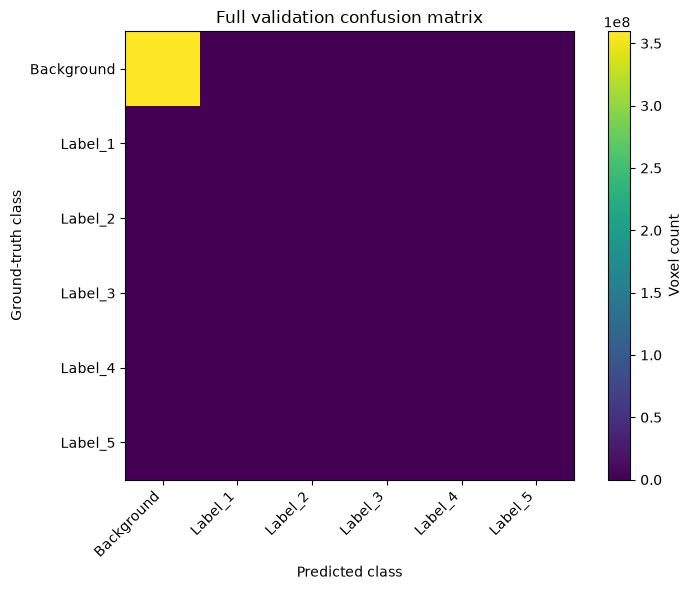

In [78]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model.eval()

confusion = torch.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=torch.int64,
    device=DEVICE
)

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        predictions = model(images).argmax(dim=1)

        # Rows = true class, columns = predicted class.
        encoded = masks.reshape(-1) * NUM_CLASSES + predictions.reshape(-1)

        confusion += torch.bincount(
            encoded,
            minlength=NUM_CLASSES * NUM_CLASSES
        ).reshape(NUM_CLASSES, NUM_CLASSES)

confusion_np = confusion.cpu().numpy()

confusion_df = pd.DataFrame(
    confusion_np,
    index=[f"True_{c}" for c in range(NUM_CLASSES)],
    columns=[f"Pred_{c}" for c in range(NUM_CLASSES)]
)

display(confusion_df)

plt.figure(figsize=(8, 6))
plt.imshow(confusion_np, interpolation="nearest")
plt.colorbar(label="Voxel count")
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
plt.xlabel("Predicted class")
plt.ylabel("Ground-truth class")
plt.title("Full validation confusion matrix")
plt.tight_layout()
plt.show()

In [79]:
rows = []

for cls in range(NUM_CLASSES):
    tp = confusion_np[cls, cls]
    true_count = confusion_np[cls, :].sum()
    predicted_count = confusion_np[:, cls].sum()

    dice = (
        2 * tp / (true_count + predicted_count)
        if true_count + predicted_count > 0
        else np.nan
    )

    rows.append({
        "class_id": cls,
        "class_name": CLASS_NAMES[cls],
        "ground_truth_voxels": int(true_count),
        "predicted_voxels": int(predicted_count),
        "true_positives": int(tp),
        "dice": dice
    })

class_metrics_df = pd.DataFrame(rows)
display(class_metrics_df)

foreground_dice = class_metrics_df.loc[
    class_metrics_df["class_id"] > 0, "dice"
]

print(
    "Foreground macro Dice:",
    foreground_dice.mean()
)

,class_id,class_name,ground_truth_voxels,predicted_voxels,true_positives,dice
0,0,Background,359789738,359910807,359612274,0.999339
1,1,Label_1,29268,43739,10597,0.290301
2,2,Label_2,493253,418258,346177,0.759567
3,3,Label_3,106742,127036,55853,0.477829
4,4,Label_4,137311,137393,38214,0.278219
5,5,Label_5,153832,72911,36763,0.324270


Foreground macro Dice: 0.4260374707613831


# Audit Slice level imbalance

In [80]:
from collections import Counter
import numpy as np
import nibabel as nib
import pandas as pd

slice_counts = Counter()
study_counts = Counter()
foreground_pixels_per_slice = []

for name in train_studies:
    mask_vol = np.asanyarray(
        nib.load(str(mask_map[name])).dataobj
    )

    labels_per_study = set(np.unique(mask_vol).astype(int)) - {0}

    for label in labels_per_study:
        study_counts[label] += 1

    for z in range(mask_vol.shape[2]):
        mask_slice = mask_vol[:, :, z]
        labels, counts = np.unique(mask_slice, return_counts=True)

        foreground = int(counts[labels != 0].sum())
        foreground_pixels_per_slice.append(foreground)

        if foreground == 0:
            slice_counts["background_only"] += 1
        else:
            slice_counts["foreground_present"] += 1

        for label in labels[labels != 0]:
            slice_counts[int(label)] += 1

print("Slice summary:")
print("Background-only slices:", slice_counts["background_only"])
print("Slices with foreground:", slice_counts["foreground_present"])

print("\nStudies containing each class:")
for cls in range(1, 6):
    print(f"Label {cls}: {study_counts[cls]} / {len(train_studies)} studies")

print("\nForeground pixels per slice:")
print(pd.Series(foreground_pixels_per_slice).describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
))

Slice summary:
Background-only slices: 3146
Slices with foreground: 1882

Studies containing each class:
Label 1: 20 / 153 studies
Label 2: 101 / 153 studies
Label 3: 82 / 153 studies
Label 4: 87 / 153 studies
Label 5: 58 / 153 studies

Foreground pixels per slice:
count     5028.000000
mean       888.273071
std       2159.955271
min          0.000000
50%          0.000000
75%        519.750000
90%       2958.600000
95%       5555.400000
99%      10468.070000
max      19426.000000
dtype: float64


Mean max probability: 0.9996206760406494
Mean predictive entropy: 0.0020808223634958267
Mean entropy normalized by log(6): 0.0011613292153924704
Class 0: 16746729 pixels
Class 1: 3182 pixels
Class 2: 2844 pixels
Class 3: 9585 pixels
Class 4: 4684 pixels
Class 5: 10192 pixels


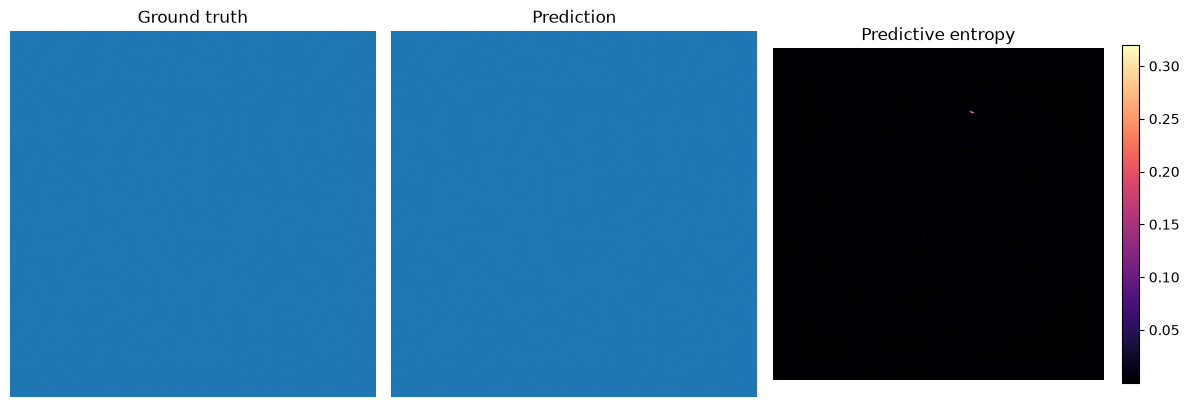

In [81]:
import torch
import numpy as np
import matplotlib.pyplot as plt

model.eval()

images, masks = next(iter(val_loader))
images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    logits = model(images)
    probs = torch.softmax(logits, dim=1)
    preds = probs.argmax(dim=1)
    confidence = probs.max(dim=1).values
    entropy = -(probs * probs.clamp_min(1e-8).log()).sum(dim=1)

print("Mean max probability:", confidence.mean().item())
print("Mean predictive entropy:", entropy.mean().item())
print("Mean entropy normalized by log(6):",
      (entropy / np.log(6)).mean().item())

# Distribution of predicted classes across this batch
for cls in range(6):
    print(
        f"Class {cls}:",
        (preds == cls).sum().item(),
        "pixels"
    )

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(masks[0].cpu(), vmin=0, vmax=5, cmap="tab10")
plt.title("Ground truth")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(preds[0].cpu(), vmin=0, vmax=5, cmap="tab10")
plt.title("Prediction")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(entropy[0].cpu(), cmap="magma")
plt.title("Predictive entropy")
plt.colorbar(fraction=0.046)
plt.axis("off")

plt.tight_layout()
plt.show()

In [82]:
from collections import Counter
import numpy as np
import nibabel as nib
import pandas as pd

slice_records = []

for name in train_studies:
    mask_vol = np.asanyarray(
        nib.load(str(mask_map[name])).dataobj
    )

    for z in range(mask_vol.shape[2]):
        mask_slice = mask_vol[:, :, z]
        labels, counts = np.unique(mask_slice, return_counts=True)

        foreground_counts = {
            int(label): int(count)
            for label, count in zip(labels, counts)
            if label != 0
        }

        record = {
            "study": name,
            "slice": z,
            "foreground_pixels": sum(foreground_counts.values()),
            "labels_present": sorted(foreground_counts.keys())
        }

        for cls in range(1, 6):
            record[f"class_{cls}_pixels"] = foreground_counts.get(cls, 0)

        slice_records.append(record)

slice_df = pd.DataFrame(slice_records)

print("Total training slices:", len(slice_df))
print("Background-only slices:", (slice_df["foreground_pixels"] == 0).sum())
print("Slices containing foreground:", (slice_df["foreground_pixels"] > 0).sum())

print("\nSlices containing each class:")
for cls in range(1, 6):
    print(f"Class {cls}: {(slice_df[f'class_{cls}_pixels'] > 0).sum()} slices")

display(slice_df.head())

Total training slices: 5028
Background-only slices: 3146
Slices containing foreground: 1882

Slices containing each class:
Class 1: 160 slices
Class 2: 727 slices
Class 3: 564 slices
Class 4: 765 slices
Class 5: 611 slices


,study,slice,foreground_pixels,labels_present,class_1_pixels,class_2_pixels,class_3_pixels,class_4_pixels,class_5_pixels
0,ID_0237f3c9_ID_40015688b9.nii.gz,0,0,[],0,0,0,0,0
1,ID_0237f3c9_ID_40015688b9.nii.gz,1,0,[],0,0,0,0,0
2,ID_0237f3c9_ID_40015688b9.nii.gz,2,0,[],0,0,0,0,0
3,ID_0237f3c9_ID_40015688b9.nii.gz,3,0,[],0,0,0,0,0
4,ID_0237f3c9_ID_40015688b9.nii.gz,4,0,[],0,0,0,0,0


In [83]:
import inspect

print(inspect.getsource(preprocessing.MultiHUWindowStack))
print(inspect.getsource(preprocessing.load_volume_as_hu))

class MultiHUWindowStack:
    """
    Converts a single 2D HU slice into a multi-channel [0, 1] stack, one
    channel per clinical window. Default: Brain / Subdural / Bone, matching
    the Week 2 spec.

    Each channel = clip(hu, lo, hi) rescaled linearly to [0, 1].
    """

    def __init__(self, windows: Tuple[Window, ...] = DEFAULT_WINDOWS):
        self.windows = windows

    def __call__(self, hu_slice: np.ndarray) -> np.ndarray:
        """
        hu_slice: (H, W) float array of HU values.
        returns:  (num_windows, H, W) float32 array in [0, 1].
        """
        if hu_slice.ndim != 2:
            raise ValueError(f"Expected a 2D (H, W) HU slice, got shape {hu_slice.shape}")

        channels = []
        for w in self.windows:
            clipped = np.clip(hu_slice, w.lo, w.hi)
            scaled = (clipped - w.lo) / (w.hi - w.lo)  # -> [0, 1]
            channels.append(scaled.astype(np.float32))

        return np.stack(channels, axis=0)  # (C, H, W)

def load_volu

# Model Card

In [85]:
import json
import platform
import hashlib
from pathlib import Path
import torch
import pandas as pd

OUTPUT_DIR = Path("C:/Users/whate/Documents/Brain CT Hemorrage Detection/week4_outputs")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"

# Export the full validation metrics already computed in Cell 27.
class_metrics_df.to_csv(
    OUTPUT_DIR / "validation_per_class_metrics.csv",
    index=False
)

pd.DataFrame(confusion_np).to_csv(
    OUTPUT_DIR / "validation_confusion_matrix.csv",
    index=False,
    header=False
)

with open(OUTPUT_DIR / "smoke_test_history.json", "w") as f:
    json.dump(history, f, indent=2, allow_nan=False)

# Configuration: record the actual choices used.
config = {
    "experiment_id": "baseline_smoke_test_v1",
    "architecture": "UNet25D",
    "input_channels": 9,
    "output_classes": 6,
    "base_channels": 16,
    "dropout_type": "Dropout2d",
    "dropout_probability": 0.2,
    "loss": "CrossEntropy + foreground multiclass soft Dice",
    "dice_weight": DICE_WEIGHT,
    "optimizer": "AdamW",
    "initial_learning_rate": 0.001,
    "weight_decay": 0.0001,
    "scheduler": "CosineAnnealingLR",
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "train_negative_ratio": TRAIN_NEGATIVE_RATIO,
    "cache_all_volumes": CACHE_ALL_VOLUMES,
    "num_workers": NUM_WORKERS,
    "amp_enabled": AMP_ENABLED,
    "amp_dtype": str(AMP_DTYPE) if AMP_ENABLED else "disabled",
    "compiled": COMPILE_MODEL,
    "input_resolution": [512, 512],
    "input_window_channels_per_slice": 3,
    "neighboring_slices": 3,
    "seed": SEED,
    "training_studies": len(train_studies),
    "validation_studies": len(val_studies),
    "split_file": str(OUTPUT_DIR / "development_split.json"),
    "preprocessing_file": str(PREPROCESSING_FILE),
    "device": torch.cuda.get_device_name(0)
              if torch.cuda.is_available() else "CPU",
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "dataset_provenance": "Pending team confirmation",
    "clinical_label_mapping": "Pending confirmation",
    "intensity_padding_convention": "Pending confirmation",
    "active_learning_pool_overlap": "Not yet verified",
    "purpose": "Three-epoch engineering smoke test; not a final performance evaluation"
}

with open(OUTPUT_DIR / "training_config.json", "w") as f:
    json.dump(config, f, indent=2)

# Model card: distinguish verified facts from unresolved assumptions.
model_card = {
    "model_name": "mLHealth 360 - 2.5D U-Net",
    "version": "baseline_smoke_test_v1",
    "intended_use": "Development baseline for medical image segmentation research",
    "not_for_clinical_use": True,
    "architecture": "2.5D U-Net",
    "parameter_count": sum(p.numel() for p in model.parameters()),
    "input_shape_per_sample": [9, 512, 512],
    "output_shape_per_sample": [6, 512, 512],
    "mask_ids_observed": [0, 1, 2, 3, 4, 5],
    "clinical_class_mapping": "Unconfirmed",
    "dropout_layers": len(dropout_layers),
    "dropout_probability": 0.2,
    "training_studies": len(train_studies),
    "validation_studies": len(val_studies),
    "training_epochs": len(history),
    "best_validation_macro_dice": float(best_macro_dice),
    "limitations": [
        "Dataset provenance requires confirmation",
        "Clinical meaning of mask IDs requires confirmation",
        "Only three training epochs completed",
        "Small and imbalanced validation subset",
        "Active Learning pool overlap has not been verified",
        "Stored image intensity and padding convention require confirmation"
    ],
    "checkpoint": str(best_path)
}

with open(OUTPUT_DIR / "model_card.json", "w") as f:
    json.dump(model_card, f, indent=2)

print("Saved:")
for filename in [
    "training_config.json",
    "model_card.json",
    "smoke_test_history.json",
    "validation_per_class_metrics.csv",
    "validation_confusion_matrix.csv"
]:
    print(" -", OUTPUT_DIR / filename)

Saved:
 - C:\Users\whate\Documents\Brain CT Hemorrage Detection\week4_outputs\training_config.json
 - C:\Users\whate\Documents\Brain CT Hemorrage Detection\week4_outputs\model_card.json
 - C:\Users\whate\Documents\Brain CT Hemorrage Detection\week4_outputs\smoke_test_history.json
 - C:\Users\whate\Documents\Brain CT Hemorrage Detection\week4_outputs\validation_per_class_metrics.csv
 - C:\Users\whate\Documents\Brain CT Hemorrage Detection\week4_outputs\validation_confusion_matrix.csv


# Verify checkpoint reload

In [86]:
import torch

checkpoint = torch.load(
    best_path,
    map_location=DEVICE,
    weights_only=False
)

reloaded_model = UNet25D(
    in_channels=9,
    num_classes=6,
    base_channels=16,
    dropout_p=0.2
).to(DEVICE)

reloaded_model.load_state_dict(
    checkpoint["model_state_dict"]
)
reloaded_model.eval()

model.eval()

images, _ = next(iter(val_loader))
images = images.to(DEVICE)

with torch.no_grad():
    original_logits = model(images)
    reloaded_logits = reloaded_model(images)

max_difference = (
    original_logits - reloaded_logits
).abs().max().item()

print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint file:", best_path)
print("Max logit difference after reload:", max_difference)

assert torch.allclose(
    original_logits, reloaded_logits,
    atol=1e-6, rtol=1e-5
), "Reloaded model predictions differ."

print("PASS: checkpoint reload reproduces predictions.")

Checkpoint epoch: 33
Checkpoint file: C:\Users\whate\Documents\Brain CT Hemorrage Detection\week4_outputs\checkpoints\best_model.pt
Max logit difference after reload: 0.0
PASS: checkpoint reload reproduces predictions.


In [87]:
reloaded_model.train()
reloaded_model.zero_grad(set_to_none=True)

images, masks = next(iter(train_loader))
images = images.to(DEVICE)
masks = masks.to(DEVICE)

logits = reloaded_model(images)
logits.retain_grad()

loss, parts = combined_loss(logits, masks)
loss.backward()

channel_gradients = (
    logits.grad.abs().sum(dim=(0, 2, 3))
).detach().cpu()

print("Loss:", parts)

for cls, grad in enumerate(channel_gradients.tolist()):
    print(f"Output channel {cls}: {grad:.6e}")

assert torch.isfinite(channel_gradients).all()
assert (channel_gradients > 0).all()

print("PASS: all six output channels receive nonzero gradients.")

Loss: {'cross_entropy': 0.019632546231150627, 'dice_loss': 0.5329958200454712, 'total_loss': 0.5526283383369446}
Output channel 0: 2.928361e-02
Output channel 1: 1.469670e-02
Output channel 2: 8.136585e-03
Output channel 3: 1.082183e-02
Output channel 4: 1.462277e-02
Output channel 5: 1.574618e-02
PASS: all six output channels receive nonzero gradients.


# Final Week 4 Verification

In [89]:
from pathlib import Path

ROOT = Path("C:/Users/whate/Documents/Brain CT Hemorrage Detection/week4_outputs")

expected_files = [
    "training_config.json",
    "model_card.json",
    "smoke_test_history.json",
    "validation_per_class_metrics.csv",
    "validation_confusion_matrix.csv",
    "smoke_test_curves.png",
    "development_split.json",
    "checkpoints/best_model.pt",
    "checkpoints/last_model.pt",
]

print("WEEK 4 ARTIFACT AUDIT")
print("=" * 60)

all_ok = True

for relative_path in expected_files:
    path = ROOT / relative_path
    exists = path.is_file()
    size = path.stat().st_size if exists else 0
    passed = exists and size > 0

    print(
        f"{'PASS' if passed else 'MISSING'} | "
        f"{relative_path} | {size:,} bytes"
    )

    all_ok &= passed

print("=" * 60)
print("ALL ARTIFACTS PRESENT:", all_ok)

WEEK 4 ARTIFACT AUDIT
PASS | training_config.json | 1,465 bytes
PASS | model_card.json | 1,191 bytes
PASS | smoke_test_history.json | 9,048 bytes
PASS | validation_per_class_metrics.csv | 392 bytes
PASS | validation_confusion_matrix.csv | 202 bytes
PASS | smoke_test_curves.png | 79,061 bytes
PASS | development_split.json | 8,042 bytes
PASS | checkpoints/best_model.pt | 5,885,059 bytes
PASS | checkpoints/last_model.pt | 5,885,059 bytes
ALL ARTIFACTS PRESENT: True
